# E2 · Serie de tiempo y regresión por mínimos cuadrados
Venta diaria de Salomé por fecha de entrega. Incluye la semana del 25 al 31 de octubre de 2026 que entró por la tubería.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent
sys.path += [str(RAIZ / "services/tablero"), str(RAIZ / "services/worker")]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import analitica as an, modelos_e2 as m2
from limpieza import limpiar, validar_limpio
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [2]:
df = an.preparar(pd.read_csv(RAIZ / "data/historial/pedidos_salome_clean.csv"))
cierres = pd.read_csv(RAIZ / "services/worker/referencia/calendario_cierres.csv")["fecha"]
s = an.serie_diaria(df)
s22 = s[s.index >= m2.INICIO_MODELO]
print(s.index.min().date(), "a", s.index.max().date(), len(s), "días;", "desde 2022:", len(s22))

2020-02-06 a 2026-10-31 2460 días; desde 2022: 1765


## 1. Descomposición
STL con periodo 7 sobre la venta diaria desde 2022 (antes el negocio estaba arrancando) y descomposición clásica multiplicativa con periodo 12 sobre la venta mensual.

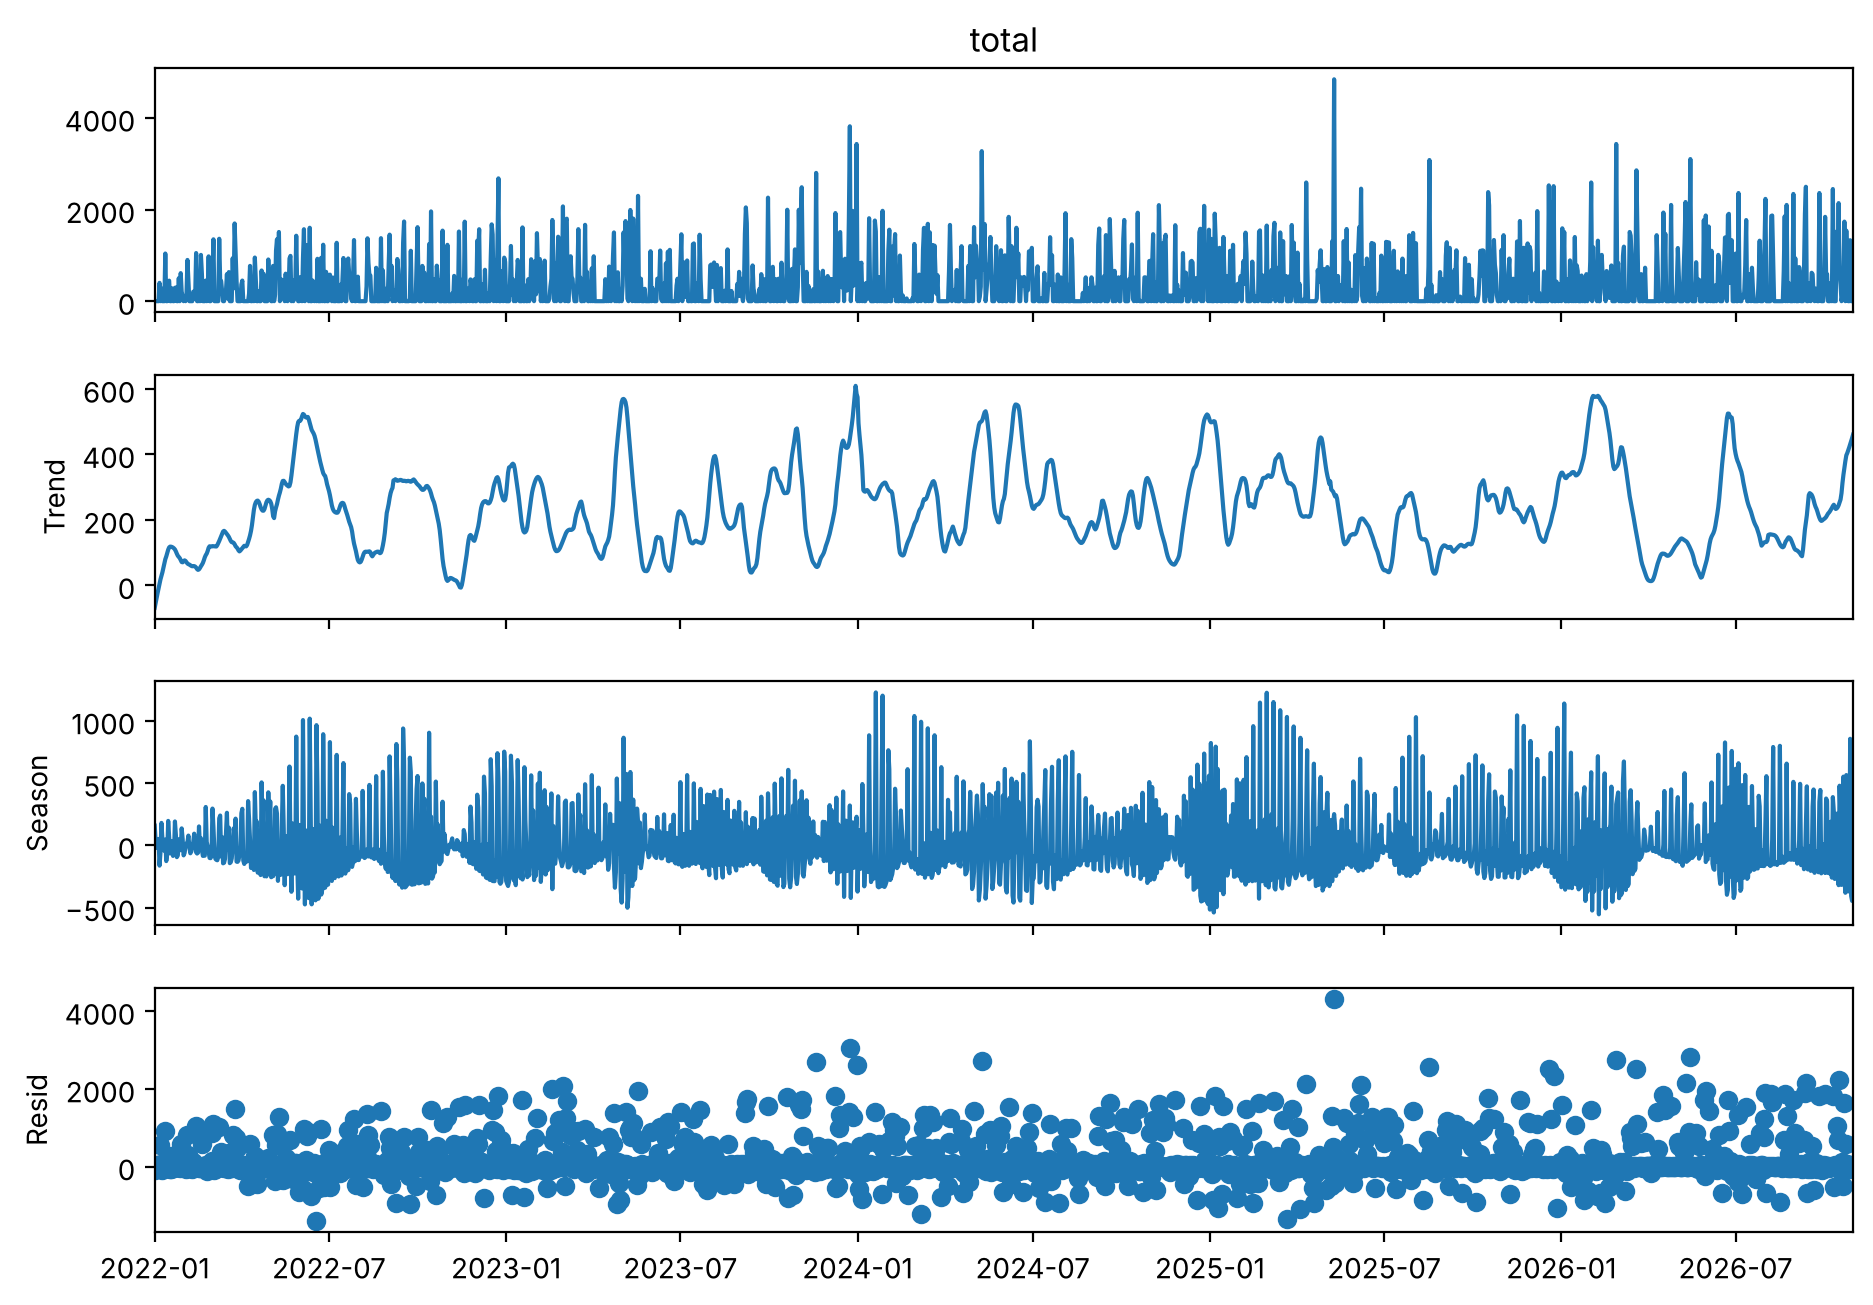

{'tendencia': np.float64(0.046),
 'estacional': np.float64(0.248),
 'residuo': np.float64(0.791)}

In [3]:
stl = m2.descomposicion(df)
fig = stl.plot(); fig.set_size_inches(10, 7); plt.show()
partes = {"tendencia": stl.trend.var(), "estacional": stl.seasonal.var(), "residuo": stl.resid.var()}
{k: round(v / stl.observed.var(), 3) for k, v in partes.items()}

In [4]:
stl.seasonal.groupby(stl.seasonal.index.dayofweek).mean().rename(dict(enumerate(an.DIAS))).round(0)

lunes       -232.00
martes      -112.00
miércoles    -52.00
jueves       -30.00
viernes       69.00
sábado       293.00
domingo       64.00
Name: season, dtype: float64

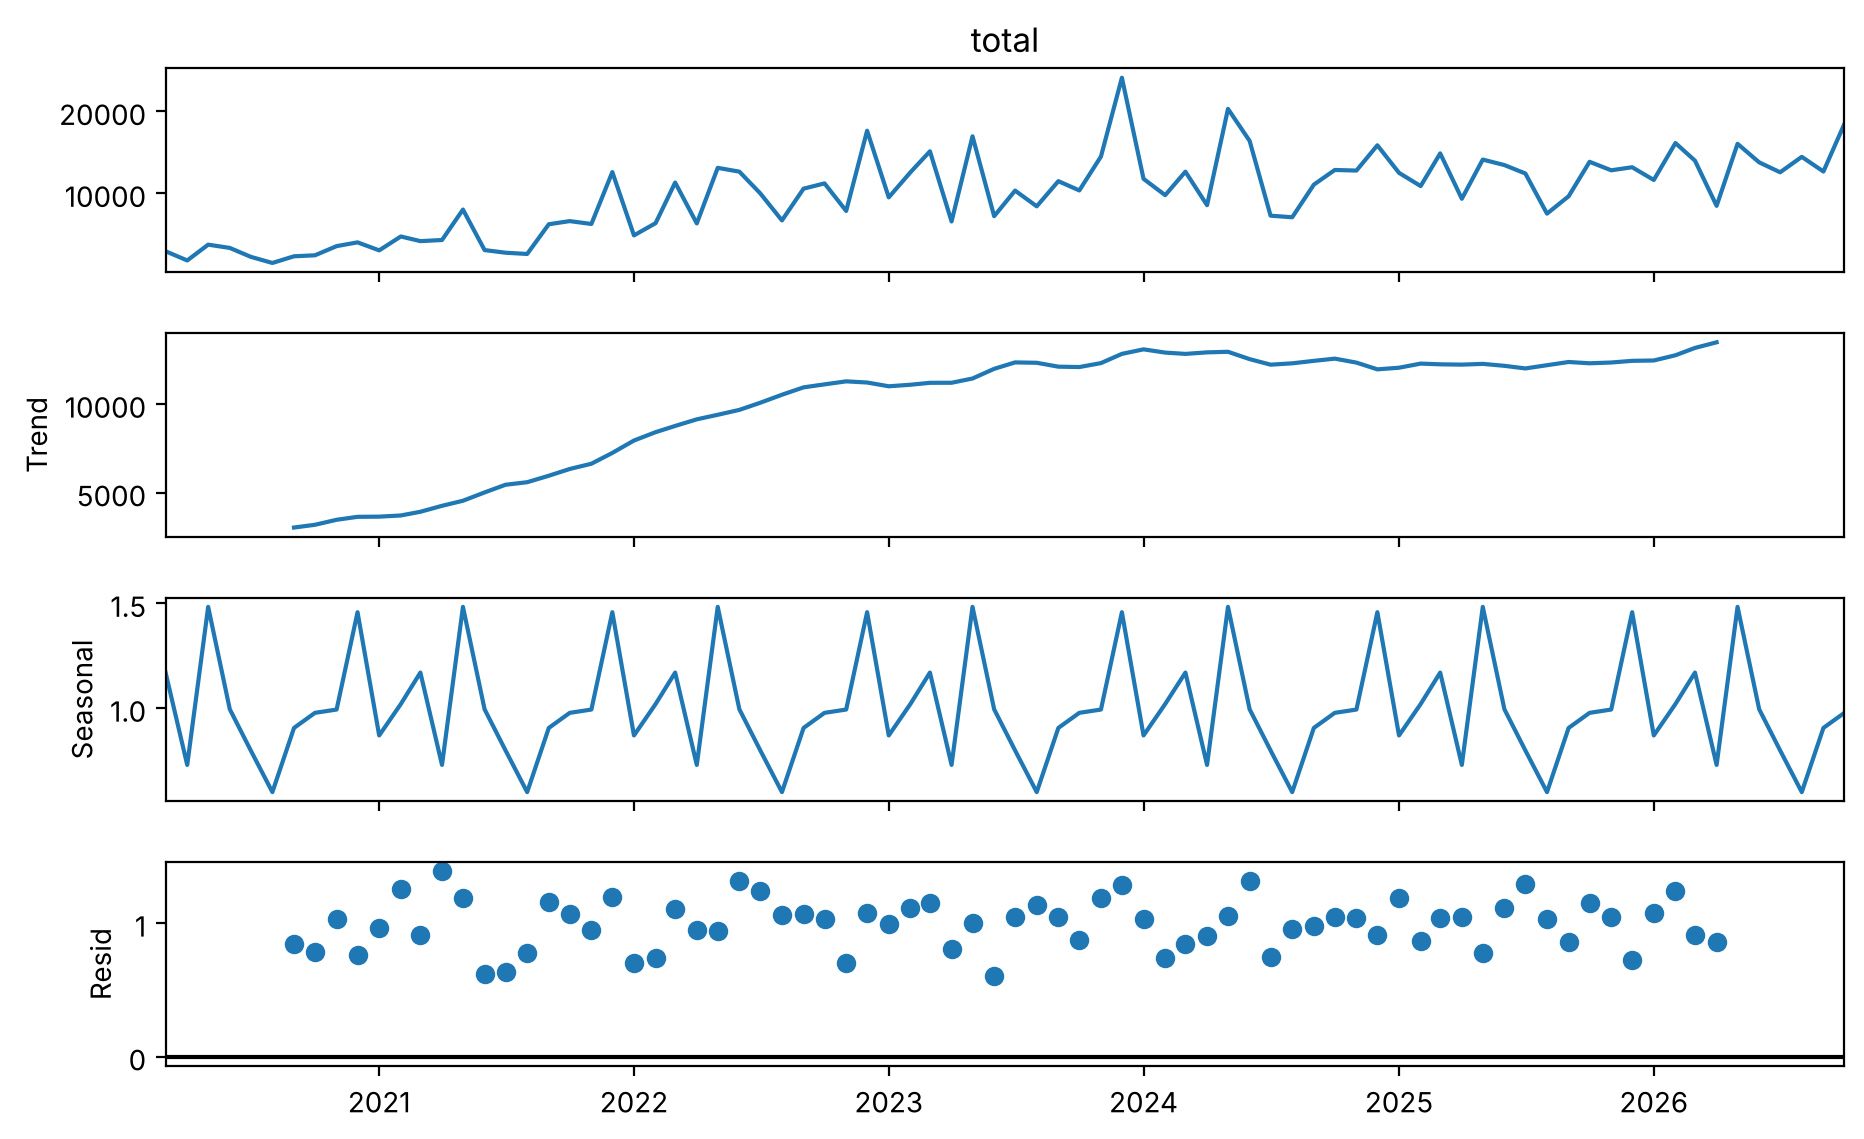

fecha_entrega
enero        0.87
febrero      1.02
marzo        1.17
abril        0.73
mayo         1.48
junio        0.99
julio        0.80
agosto       0.60
septiembre   0.91
octubre      0.98
noviembre    0.99
diciembre    1.46
Name: seasonal, dtype: float64

In [5]:
dm = m2.descomposicion_mensual(df)
fig = dm.plot(); fig.set_size_inches(10, 6); plt.show()
dm.seasonal.iloc[:12].sort_index(key=lambda i: i.month).rename(lambda i: an.MESES[i.month - 1]).round(3)

## 2. Estacionariedad (Dickey-Fuller aumentada)
H0: la serie tiene raíz unitaria (no es estacionaria).

In [6]:
mens = df.groupby(df.fecha_entrega.dt.to_period("M")).total.sum()
mens = mens[(mens.index >= "2020-03") & (mens.index <= "2026-10")].astype(float)
pruebas = {"diaria desde 2022 (constante)": m2.adf(s22), "diaria desde 2022 (constante y tendencia)": m2.adf(s22, "ct"),
           "diaria 2020-2026 (constante y tendencia)": m2.adf(s, "ct"), "diaria, diferencia de 7 días": m2.adf(s22.diff(7)),
           "mensual 2020-2026": m2.adf(mens), "mensual, primera diferencia": m2.adf(mens.diff())}
pd.DataFrame(pruebas).T[["estadistico", "critico_5", "p_valor", "rezagos", "estacionaria_5"]]

,estadistico,critico_5,p_valor,rezagos,estacionaria_5
diaria desde 2022 (constante),-8.55,-2.86,0.00,22,True
diaria desde 2022 (constante y tendencia),-8.88,-3.41,0.00,22,True
diaria 2020-2026 (constante y tendencia),-7.99,-3.41,0.00,27,True
"diaria, diferencia de 7 días",-14.12,-2.86,0.00,21,True
mensual 2020-2026,-2.12,-2.91,0.23,11,False
"mensual, primera diferencia",-4.71,-2.91,0.00,10,True


## 3. ACF y PACF

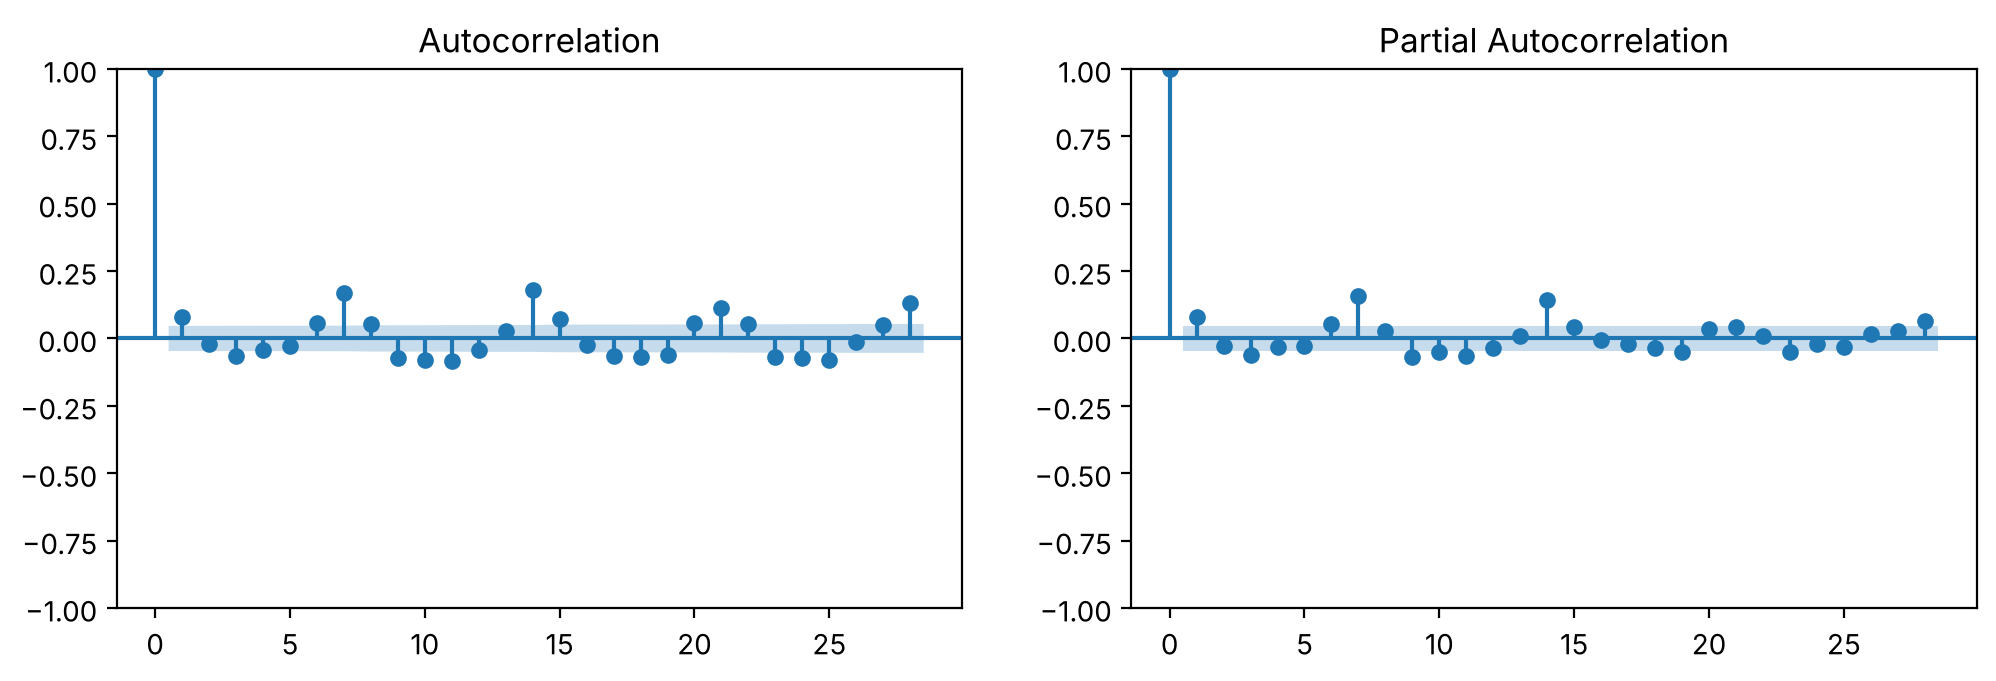

,ACF,PACF
1,0.08,0.08
2,-0.02,-0.03
6,0.06,0.06
7,0.17,0.16
8,0.05,0.03
14,0.18,0.14
21,0.11,0.04
28,0.13,0.07


In [7]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(s22, lags=28, ax=ax[0]); plot_pacf(s22, lags=28, ax=ax[1], method="ywm"); plt.show()
pd.DataFrame({"ACF": acf(s22, nlags=28), "PACF": pacf(s22, nlags=28)}).iloc[[1, 2, 6, 7, 8, 14, 21, 28]].round(3)

## 4. Regresión lineal por mínimos cuadrados, a mano
y = venta del día (solo días que Salomé abrió). X = intercepto, tendencia en años, día de la semana (base martes), mes (base enero), quincena, fecha fuerte y víspera de fecha fuerte. Entrenamiento: 2022-01-01 a 2025-10-31; prueba: 2025-11-01 a 2026-10-31.

β = (XᵀX)⁻¹ Xᵀ y

In [8]:
d = m2.datos_modelo(df, cierres)
X = m2.matriz_diseno(d.index)
tr = d.index < m2.CORTE_PRUEBA
Xtr, ytr, Xte, yte = X[tr].to_numpy(), d.venta[tr].to_numpy(), X[~tr].to_numpy(), d.venta[~tr].to_numpy()
XtX = Xtr.T @ Xtr
beta = np.linalg.inv(XtX) @ Xtr.T @ ytr          # la ecuación normal, tal cual
print("X:", Xtr.shape, " número de condición de XᵀX:", round(np.linalg.cond(XtX)))

X: (1144, 21)  número de condición de XᵀX: 860


Errores estándar con la fórmula clásica: σ̂² = SSE / (n − p) y Var(β̂) = σ̂² (XᵀX)⁻¹.

In [9]:
from scipy import stats
e = ytr - Xtr @ beta
n, p = Xtr.shape
sigma2 = e @ e / (n - p)
ee = np.sqrt(np.diag(sigma2 * np.linalg.inv(XtX)))
tabla = pd.DataFrame({"beta": beta, "error_est": ee, "t": beta / ee}, index=X.columns)
tabla["p_valor"] = 2 * stats.t.sf(np.abs(tabla.t), n - p)
tabla

,beta,error_est,t,p_valor
intercepto,80.77,69.48,1.16,0.25
t_anios,35.86,14.95,2.40,0.02
miercoles,113.63,56.32,2.02,0.04
jueves,180.46,56.17,3.21,0.00
viernes,270.13,55.65,4.85,0.00
sabado,450.09,55.75,8.07,0.00
domingo,204.68,55.80,3.67,0.00
feb,35.61,77.85,0.46,0.65
mar,202.64,77.33,2.62,0.01
abr,10.64,79.72,0.13,0.89


### Comparación contra scikit-learn

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
sk = LinearRegression(fit_intercept=False).fit(Xtr, ytr)
print("diferencia máxima entre coeficientes:", np.abs(beta - sk.coef_).max())
print("diferencia máxima entre predicciones de prueba:", np.abs(Xte @ beta - sk.predict(Xte)).max())

diferencia máxima entre coeficientes: 2.5153212845907547e-12
diferencia máxima entre predicciones de prueba: 6.195932655828074e-12


In [11]:
filas = {}
for nombre, y, yhat in [("entrenamiento (a mano)", ytr, Xtr @ beta), ("prueba (a mano)", yte, Xte @ beta),
                        ("prueba (scikit-learn)", yte, sk.predict(Xte))]:
    filas[nombre] = m2.metricas(y, yhat)
ingenuo = s.shift(7).reindex(d.index[~tr]).to_numpy()
filas["prueba: ingenuo estacional"] = m2.metricas(yte, ingenuo)
filas["prueba: con t² (descartado)"] = m2.ajustar(df, cierres, cuadratica=True)["metricas_prueba"]
pd.DataFrame(filas).T

,MSE,RMSE,MAE,R2
entrenamiento (a mano),"295,093.98",543.23,420.92,0.14
prueba (a mano),"479,482.49",692.45,534.07,0.06
prueba (scikit-learn),"479,482.49",692.45,534.07,0.06
prueba: ingenuo estacional,"911,218.64",954.58,645.88,-0.78
prueba: con t² (descartado),"503,604.65",709.65,504.26,0.01


In [12]:
# sklearn.metrics da lo mismo que nuestras fórmulas
yhat = Xte @ beta
mean_squared_error(yte, yhat), np.sqrt(mean_squared_error(yte, yhat)), mean_absolute_error(yte, yhat), r2_score(yte, yhat)

(479482.48823382123,
 np.float64(692.4467403590122),
 534.0667208889481,
 0.062121652902518365)

### Lineal contra cuadrática: se decide con un año de validación dentro del entrenamiento

In [13]:
va, tr2 = (d.index >= "2025-01-01") & (d.index < m2.CORTE_PRUEBA), d.index < "2025-01-01"
for cuad in (False, True):
    Xv = m2.matriz_diseno(d.index, cuadratica=cuad)
    b = m2.mco(Xv[tr2].to_numpy(), d.venta[tr2].to_numpy())
    print("cuadrática" if cuad else "lineal    ", {k: round(v, 3) for k, v in m2.metricas(d.venta[va].to_numpy(), Xv[va].to_numpy() @ b).items()})
r_q = m2.ajustar(df, cierres, cuadratica=True)
print("sesgo en prueba (real − predicho): lineal", round(np.mean(yte - Xte @ beta)), " cuadrática", round(np.mean(r_q["y_te"] - r_q["pred_te"])))

lineal     {'MSE': 371963.666, 'RMSE': 609.888, 'MAE': 487.252, 'R2': 0.11}
cuadrática {'MSE': 382578.278, 'RMSE': 618.529, 'MAE': 450.408, 'R2': 0.085}


sesgo en prueba (real − predicho): lineal -4  cuadrática 136


## 5. Análisis de residuos

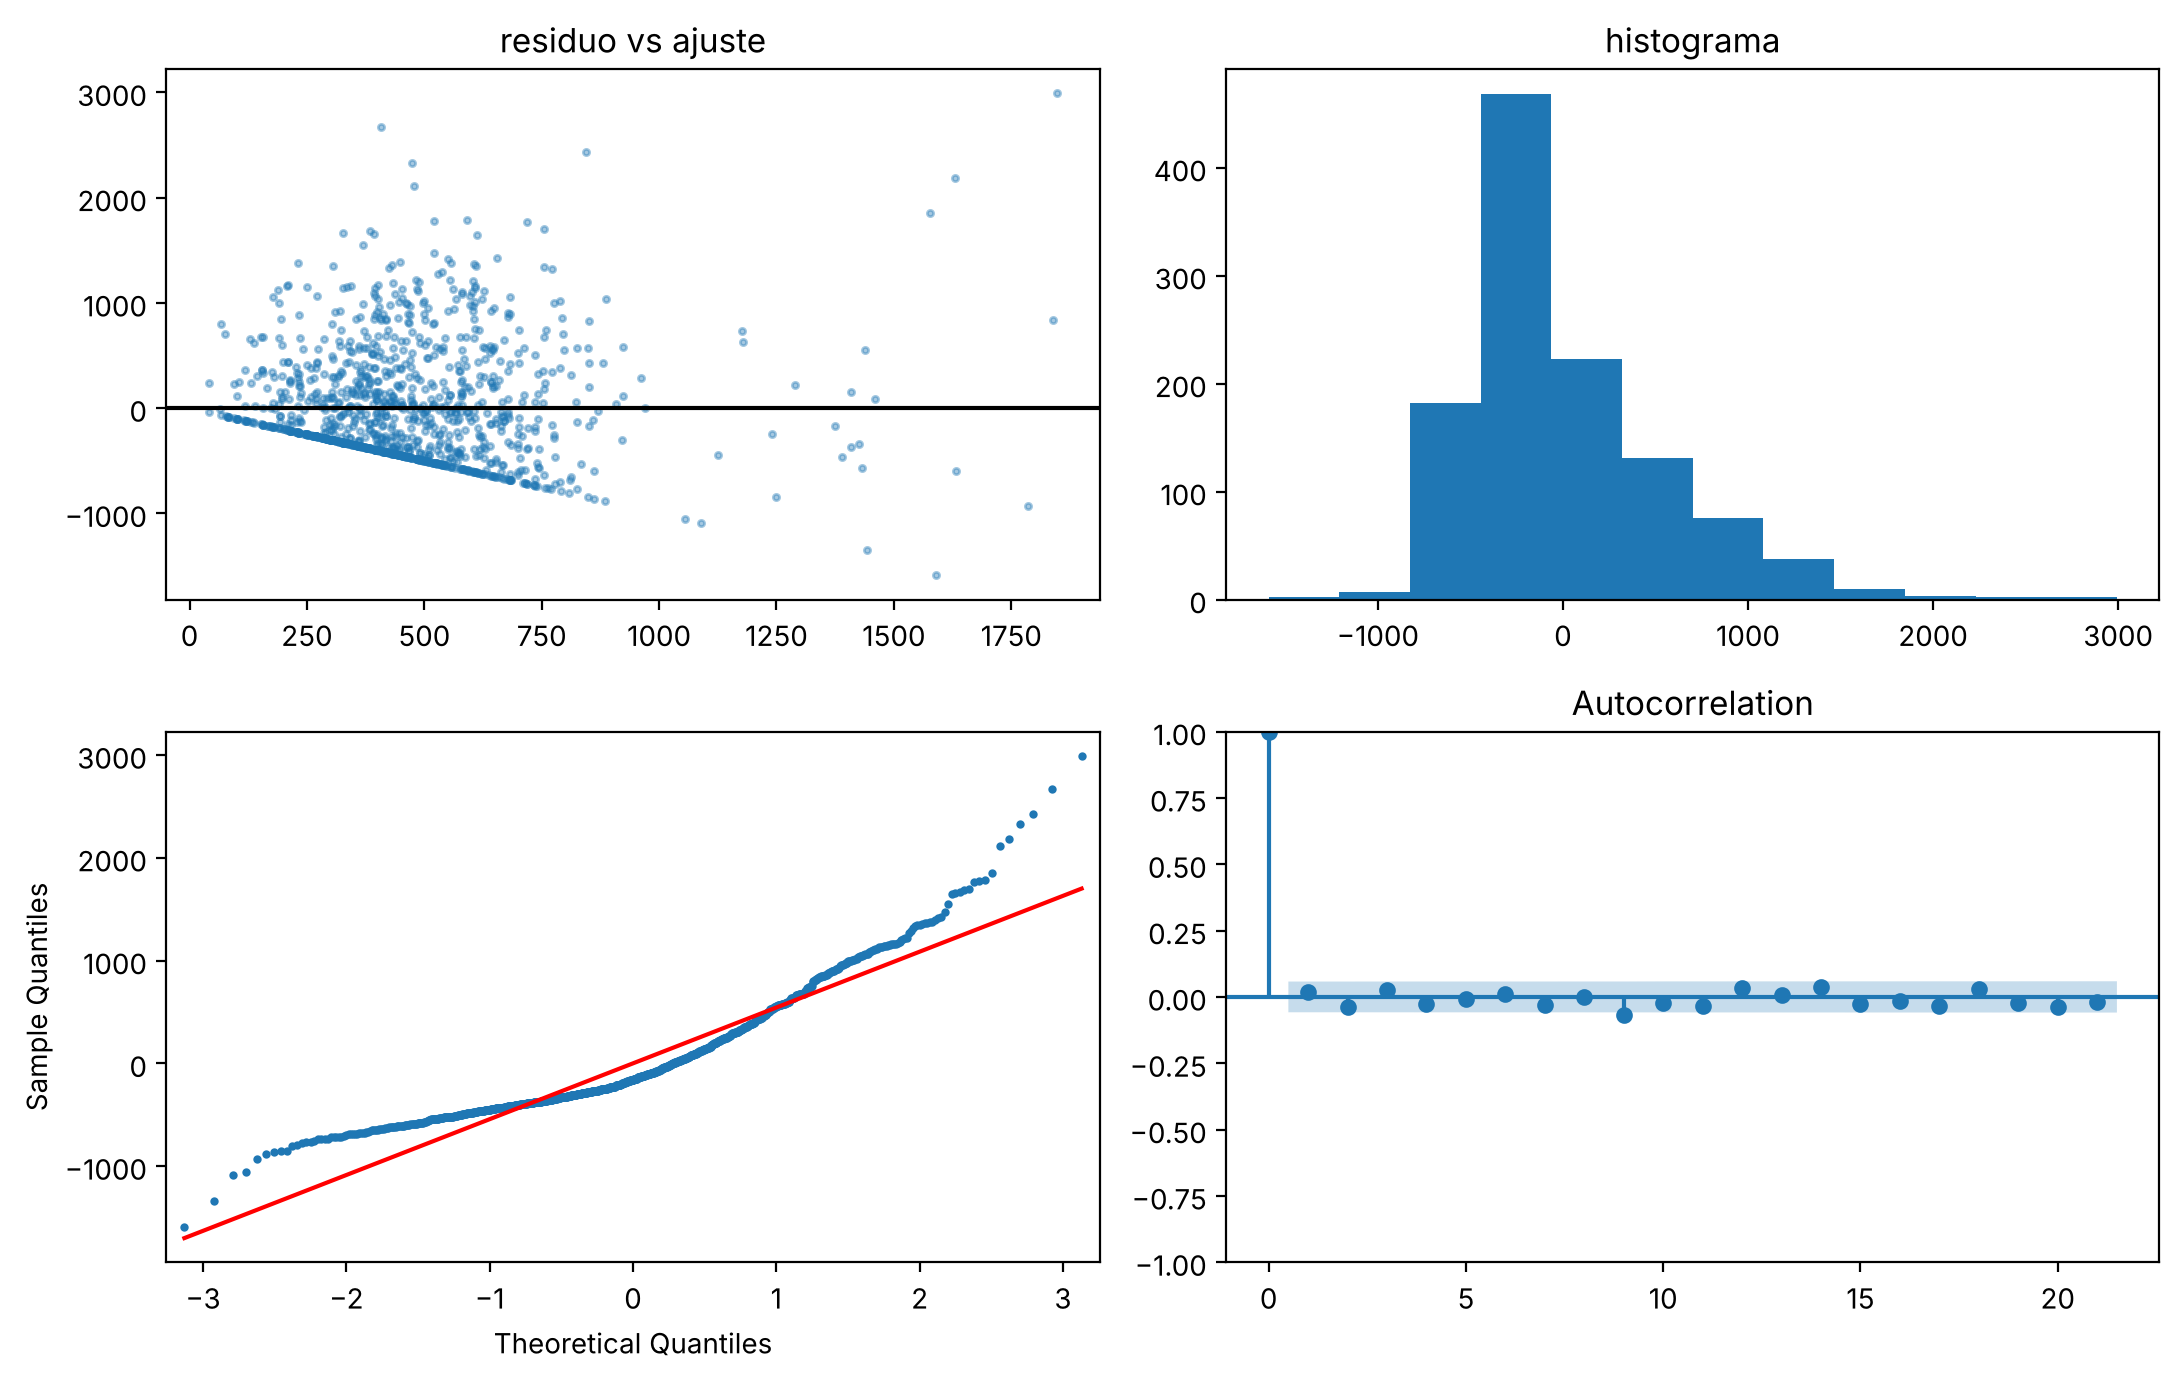

{'media': np.float64(-9.2221490739213e-13),
 'asimetría': np.float64(1.2862014843072866),
 'curtosis exceso': np.float64(2.2774547979976782),
 'Durbin-Watson': np.float64(1.9638800950853323),
 'Breusch-Pagan p': np.float64(1.054708901471673e-15),
 'Shapiro p': np.float64(3.4746944869634864e-26),
 'corr(|e|, ajuste)': np.float64(0.3291572083421046)}

In [14]:
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.graphics.gofplots import qqplot
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
ax[0, 0].scatter(Xtr @ beta, e, s=5, alpha=.4); ax[0, 0].axhline(0, color="k"); ax[0, 0].set_title("residuo vs ajuste")
ax[0, 1].hist(e, bins=int(np.ceil(np.log2(len(e)) + 1))); ax[0, 1].set_title("histograma")
qqplot(e, line="s", ax=ax[1, 0], markersize=2); plot_acf(e, lags=21, ax=ax[1, 1]); plt.tight_layout(); plt.show()
{"media": e.mean(), "asimetría": stats.skew(e), "curtosis exceso": stats.kurtosis(e), "Durbin-Watson": durbin_watson(e),
 "Breusch-Pagan p": het_breuschpagan(e, Xtr)[1], "Shapiro p": stats.shapiro(e).pvalue,
 "corr(|e|, ajuste)": np.corrcoef(np.abs(e), Xtr @ beta)[0, 1]}

## 6. Lo que esto deja para E3
La ACF con picos en 7, 14, 21 y 28 que bajan despacio y la PACF con picos estacionales piden un SARIMA con periodo 7 y diferencia estacional (D = 1). El ADF diario no obliga a diferenciar la parte no estacional (d = 0 o 1 se decide por AIC). La regresión queda como línea base explicable: le gana al ingenuo estacional, pero con poco más de un pedido diario explica muy poco de la variación de un día, y sus residuos crecen en los días grandes. En E3 conviene probar también la escala semanal.